# AP por umbral de IoU y curvas Precision-Recall completas

1. **AP por umbral de IoU** (0.50 a 0.95).
2. **Curva PR completa por clase a IoU=0.5.**

## De dónde salen los datos

`evaluate.py` activa `extended_summary=True` en
`torchmetrics.MeanAveragePrecision` y escribe en `eval_results.json` los campos
`ap_por_iou`, `iou_thresholds` y, por clase, `pr_curve_iou50` (101 puntos de
recall, rejilla estándar COCO). Esta curva (pycocotools) no es la del punto de
máximo F1 de la tabla P/R/F1.

Los runs evaluados sin estos campos se omiten y se avisa.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUNS = Path("../runs")
FIG_DIR = Path("figuras_pr_iou")
FIG_DIR.mkdir(exist_ok=True)
SEMILLAS = (0, 1, 2)

CONFIGS = [
    ("YOLO11m (A)",  "yolo_a_final"),
    ("YOLO11m (B)",  "yolo_b_final"),
    ("Faster R-CNN", "frcnn_final"),
    ("SSD300",       "ssd_final"),
    ("DETR",         "detr_final"),
    ("CNN baseline", "cnnb_final"),
]
CLASS_NAMES = ["person", "rider", "car", "truck", "bus",
               "train", "motor", "bike", "traffic light", "traffic sign"]

MODEL_COLORS = {
    "YOLO11m (A)":  "#2a78d6",
    "YOLO11m (B)":  "#eb6834",
    "Faster R-CNN": "#1baf7a",
    "SSD300":       "#eda100",
    "DETR":         "#e87ba4",
    "CNN baseline": "#008300",
}
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_COLOR, "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.axisbelow": True,
    "font.size": 10.5, "figure.dpi": 110,
})


def buscar_json(run_name: str):
    cands = [p / run_name / "eval_results.json" for p in RUNS.glob("*") if p.is_dir()]
    for c in cands:
        if c.exists():
            return c
    for pat in (f"**/{run_name}/eval_results.json", f"**/{run_name}/weights/eval_results.json"):
        hit = sorted(RUNS.glob(pat))
        if hit:
            return hit[0]
    return None


def cargar(prefijo: str) -> tuple:
    datos, faltan, sin_campo_nuevo = [], [], []
    for s in SEMILLAS:
        name = f"{prefijo}_s{s}"
        p = buscar_json(name)
        if p is None:
            faltan.append(name)
            continue
        d = json.loads(p.read_text(encoding="utf-8"))
        if "ap_por_iou" not in d or not d["ap_por_iou"]:
            sin_campo_nuevo.append(name)
            continue
        d["_run"] = name
        datos.append(d)
    return datos, faltan, sin_campo_nuevo


todo, faltantes_totales, sin_campo_totales = {}, [], []
for etq, prefijo in CONFIGS:
    datos, faltan, sin_campo = cargar(prefijo)
    todo[etq] = datos
    faltantes_totales += faltan
    sin_campo_totales += sin_campo

print(f"Runs con ap_por_iou/pr_curve: {sum(len(v) for v in todo.values())} / {len(CONFIGS) * len(SEMILLAS)}")
for etq, datos in todo.items():
    print(f"  {etq:<14} {len(datos)}/{len(SEMILLAS)} semillas")
if faltantes_totales:
    print(f"\nSin ningun eval_results.json: {', '.join(faltantes_totales)}")
if sin_campo_totales:
    print(f"\nEvaluados con la version ANTERIOR de evaluate.py (sin ap_por_iou/pr_curve),")
    print(f"hace falta re-evaluarlos: {', '.join(sin_campo_totales)}")

Runs con ap_por_iou/pr_curve: 18 / 18
  YOLO11m (A)    3/3 semillas
  YOLO11m (B)    3/3 semillas
  Faster R-CNN   3/3 semillas
  SSD300         3/3 semillas
  DETR           3/3 semillas
  CNN baseline   3/3 semillas


## Figura 1 — AP por umbral de IoU

Línea por modelo; sombra = ±1 desviación típica entre semillas (solo donde hay
≥ 2 semillas evaluadas con los campos nuevos).

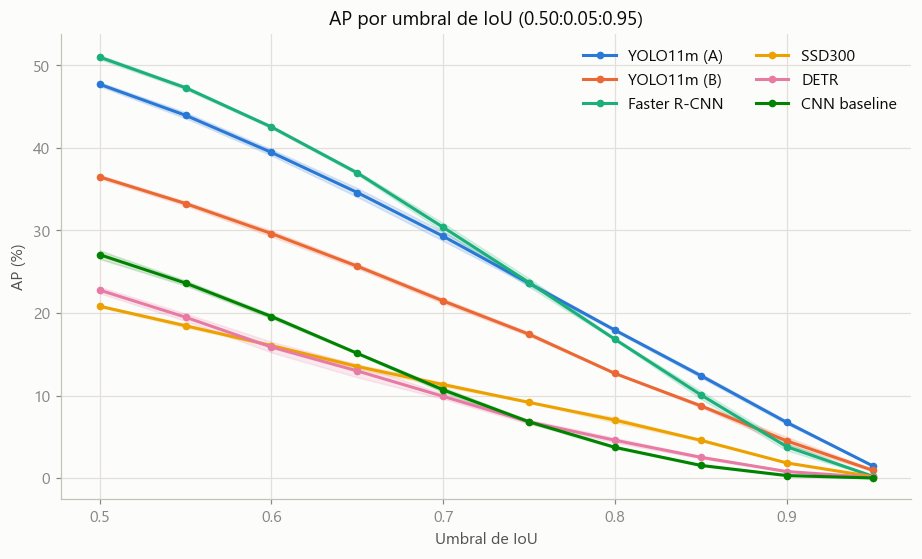

In [2]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
tiene_datos = False
for etq, _ in CONFIGS:
    datos = todo.get(etq) or []
    if not datos:
        continue
    tiene_datos = True
    iou_thr = datos[0]["iou_thresholds"]
    arr = np.array([d["ap_por_iou"] for d in datos], dtype=float)  # (n_semillas, 10)
    media = np.nanmean(arr, axis=0)
    ax.plot(iou_thr, media, color=MODEL_COLORS[etq], linewidth=2, marker="o",
            markersize=4, label=etq)
    if arr.shape[0] >= 2:
        desv = np.nanstd(arr, axis=0, ddof=1)
        ax.fill_between(iou_thr, media - desv, media + desv, color=MODEL_COLORS[etq], alpha=0.15)

if tiene_datos:
    ax.set_xlabel("Umbral de IoU")
    ax.set_ylabel("AP (%)")
    ax.set_title("AP por umbral de IoU (0.50:0.05:0.95)")
    ax.legend(frameon=False, ncol=2)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_ap_por_iou.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / "01_ap_por_iou.pdf", bbox_inches="tight")
    plt.show()
else:
    plt.close(fig)
    print("Sin datos todavia -- re-evalua al menos un run con el evaluate.py actualizado.")

## Figura 2 — Curvas Precision-Recall completas (IoU=0.5)

Cuatro clases representativas: `car` (la más frecuente), `traffic light`
(frecuente y pequeña — el caso difícil del estudio), `person` (frecuencia
media) y `rider` (rara, 121 instancias en validación). Media entre semillas
disponibles por modelo.

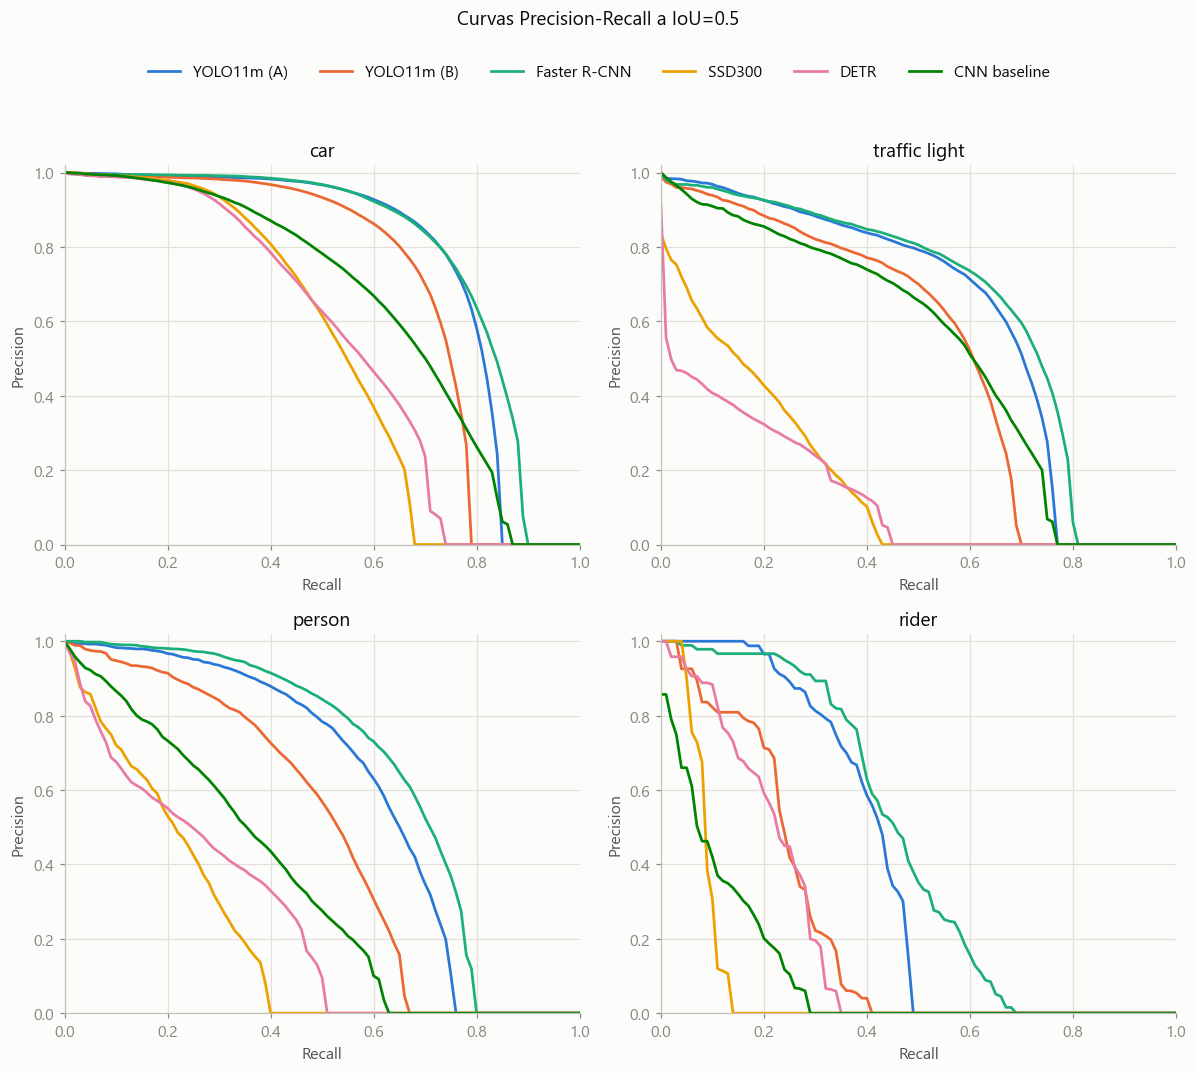

In [3]:
CLASES_FIG = ["car", "traffic light", "person", "rider"]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
alguna = False
for ax, clase in zip(axes.flat, CLASES_FIG):
    k = CLASS_NAMES.index(clase)
    x = np.linspace(0, 1, 101)
    for etq, _ in CONFIGS:
        datos = todo.get(etq) or []
        curvas = [d["per_class"][clase]["pr_curve_iou50"] for d in datos
                  if d["per_class"].get(clase, {}).get("pr_curve_iou50")]
        if not curvas:
            continue
        alguna = True
        arr = np.array(curvas, dtype=float)
        media = arr.mean(axis=0)
        ax.plot(x, media, color=MODEL_COLORS[etq], linewidth=1.8, label=etq)
    ax.set_title(clase)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

if alguna:
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=6, frameon=False)
    fig.suptitle("Curvas Precision-Recall a IoU=0.5", y=1.08)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "02_curvas_pr.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG_DIR / "02_curvas_pr.pdf", bbox_inches="tight")
    plt.show()
else:
    plt.close(fig)
    print("Sin datos todavia -- re-evalua al menos un run con el evaluate.py actualizado.")

## Resumen de ficheros generados

In [4]:
for p in sorted(FIG_DIR.glob("*.pdf")):
    print(p.name)

01_ap_por_iou.pdf
02_curvas_pr.pdf
